In [1]:
#Question 1: Medicine label reading assistant

In [2]:
#install
!pip install -q easyocr gTTS rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 297.0/297.0 kB 15.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
huggingface-hub 1.23.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
wandb 0.28.0 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.


In [3]:
#imports and OCR engine
import cv2, re, numpy as np, matplotlib.pyplot as plt, torch
from datetime import datetime
from rapidfuzz import process, fuzz
from gtts import gTTS
from IPython.display import Audio, display
from google.colab import files
import easyocr

reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available())

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Saving u1 to u1


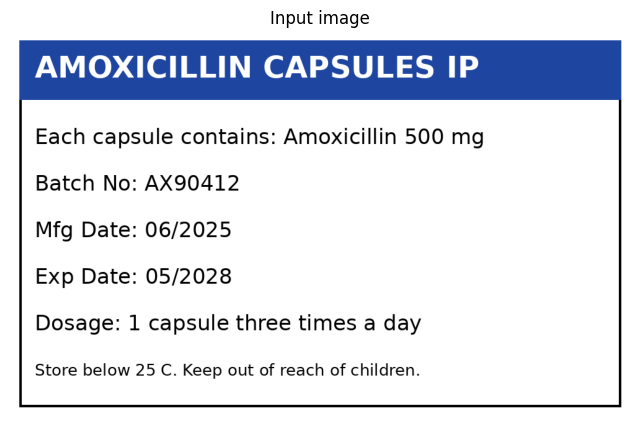

In [4]:
#load image (upload your own, or cancel to use a sample label)
def make_sample():
    img = np.full((420, 700, 3), 255, np.uint8)
    cv2.rectangle(img, (10, 10), (690, 410), (0, 0, 0), 3)
    lines = [("PARACETAMOL TABLETS IP", 1.1, 2), ("Each tablet contains: Paracetamol 500 mg", 0.7, 1),
             ("Batch No: AB12345", 0.8, 2), ("Mfg Date: 03/2025", 0.8, 1),
             ("Exp Date: 02/2028", 0.8, 1), ("Dosage: 1 tablet every 6 hours", 0.7, 1),
             ("Store below 25 C. Keep out of reach of children", 0.6, 1)]
    y = 60
    for t, s, th in lines:
        cv2.putText(img, t, (30, y), cv2.FONT_HERSHEY_SIMPLEX, s, (0, 0, 0), th, cv2.LINE_AA)
        y += 55
    return img

try:
    up = files.upload()
except Exception:
    up = {}
img = cv2.imread(list(up.keys())[0]) if up else make_sample()

plt.figure(figsize=(8, 6)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off"); plt.title("Input image"); plt.show()

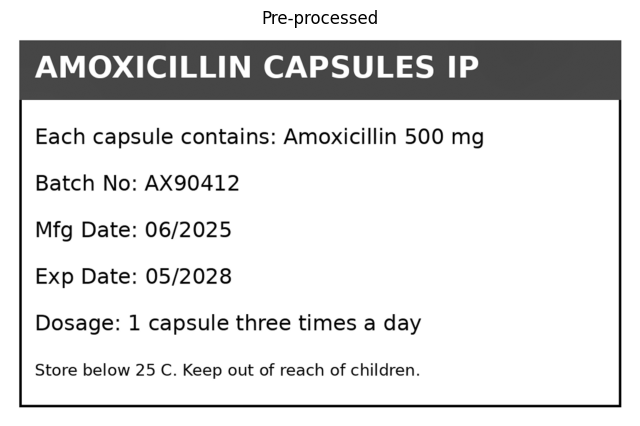

In [5]:
#pre-processing
def preprocess(bgr):
    h, w = bgr.shape[:2]
    if max(h, w) < 1200:
        s = 1200 / max(h, w)
        bgr = cv2.resize(bgr, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    gray = cv2.fastNlMeansDenoising(gray, None, 10, 7, 21)
    return bgr, gray

big, gray = preprocess(img)
plt.figure(figsize=(8, 6)); plt.imshow(gray, cmap="gray"); plt.axis("off")
plt.title("Pre-processed"); plt.show()

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


0.96 | AMOXICILLIN CAPSULES IP
0.91 | Each capsule contains: Amoxicillin 500 mg
0.76 | Batch No: AX90412
0.72 | Mfg Date: 06/2025
0.98 | Exp Date: 05/2028
0.86 | Dosage: 1 capsule three times a
0.85 | Store below 25 C. Keep out of reach of children.
1.00 | day


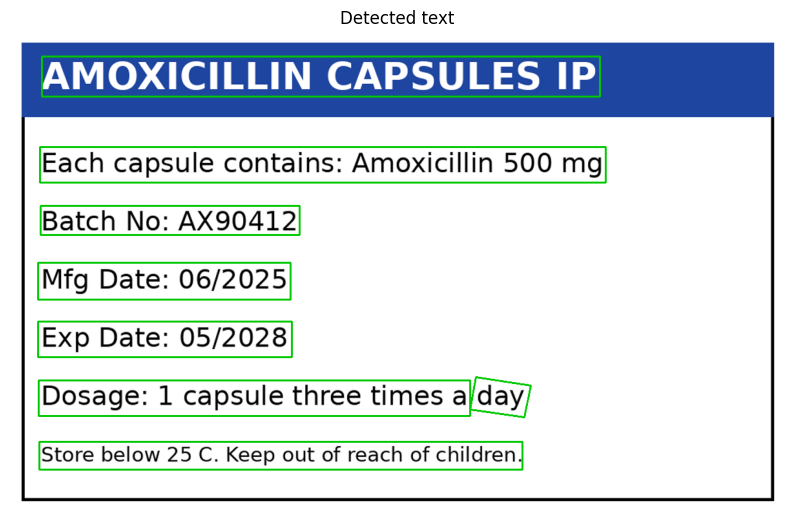

In [6]:
#run OCR
results = reader.readtext(gray)
vis = big.copy()
texts = []
for box, txt, conf in results:
    cv2.polylines(vis, [np.array(box, np.int32)], True, (0, 200, 0), 2)
    texts.append(txt)
    print(f"{conf:.2f} | {txt}")

plt.figure(figsize=(10, 7)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.axis("off"); plt.title("Detected text"); plt.show()
full_text = "\n".join(texts)

In [7]:
#extract information
KNOWN_DRUGS = ["Paracetamol","Ibuprofen","Amoxicillin","Azithromycin","Cetirizine","Metformin","Aspirin",
               "Pantoprazole","Omeprazole","Atorvastatin","Amlodipine","Losartan","Diclofenac","Ciprofloxacin",
               "Dolo","Crocin","Calpol","Combiflam","Levocetirizine","Montelukast","Ranitidine"]

def parse_date(s):
    s = s.strip().replace(".", "").replace("-", "/")
    for fmt in ("%m/%Y", "%m/%y", "%b/%Y", "%b %Y", "%B %Y", "%d/%m/%Y", "%d/%m/%y"):
        try: return datetime.strptime(s, fmt)
        except ValueError: pass
    return None

def extract_info(text):
    info = {}
    words = re.findall(r"[A-Za-z][A-Za-z0-9]{3,}", text)
    best, score = None, 0
    for w in words:
        m = process.extractOne(w, KNOWN_DRUGS, scorer=fuzz.WRatio)
        if m and m[1] > score: best, score = m[0], m[1]
    info["drug_name"] = best if score >= 80 else (words[0] if words else "Unknown")
    info["strength"] = list({f"{a} {u.lower()}" for a, u in re.findall(r"(\d+(?:\.\d+)?)\s*(mg|mcg|g|ml|iu)\b", text, re.I)})
    m = re.search(r"(?:b\.?\s*no\.?|batch(?:\s*no\.?)?)\s*[:\-]?\s*([A-Z0-9\-]{3,})", text, re.I)
    info["batch"] = m.group(1) if m else None
    datepat = r"(\d{1,2}\s*[/\-]\s*\d{2,4}|[A-Za-z]{3,9}\.?\s*\d{4})"
    m = re.search(r"(?:mfg|mfd|manufactur\w*)\.?\s*(?:date)?\s*[:\-]?\s*" + datepat, text, re.I)
    info["mfg"] = m.group(1).replace(" ", "") if m else None
    m = re.search(r"(?:exp|expiry|use\s*before)\.?\s*(?:date)?\s*[:\-]?\s*" + datepat, text, re.I)
    info["expiry"] = m.group(1).replace(" ", "") if m else None
    m = re.search(r"(?:dosage|dose|directions?|take)\s*[:\-]?\s*(.+)", text, re.I)
    info["directions"] = m.group(1).strip() if m else None
    return info

info = extract_info(full_text)
for k, v in info.items(): print(f"{k:12}: {v}")

drug_name   : Amoxicillin
strength    : ['500 mg']
batch       : AX90412
mfg         : 06/2025
expiry      : 05/2028
directions  : 1 capsule three times a


In [8]:
#assistant (expiry check and voice output)
def assistant_message(info):
    msg = [f"This looks like {info['drug_name']}."]
    if info["strength"]: msg.append("Strength is " + ", ".join(info["strength"]) + ".")
    if info["directions"]: msg.append("Directions: " + info["directions"] + ".")
    if info["batch"]: msg.append(f"Batch number {info['batch']}.")
    warning = None
    if info["expiry"]:
        d = parse_date(info["expiry"])
        if d:
            if d < datetime.now():
                warning = "Warning! This medicine appears to be EXPIRED. Do not use it."
            else:
                msg.append(f"It is valid until {d.strftime('%B %Y')}.")
    else:
        msg.append("I could not read the expiry date. Please check it manually.")
    if warning: msg.insert(0, warning)
    msg.append("Always confirm the dose with your doctor or pharmacist.")
    return " ".join(msg)

text_out = assistant_message(info)
print(text_out)
gTTS(text_out, lang="en").save("medicine_assistant.mp3")
display(Audio("medicine_assistant.mp3"))

This looks like Amoxicillin. Strength is 500 mg. Directions: 1 capsule three times a. Batch number AX90412. It is valid until May 2028. Always confirm the dose with your doctor or pharmacist.


In [9]:
#Question 2: Emotion-aware assistant using facial expression detection

In [10]:
#install
!pip install -q deepface tf-keras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.2/300.2 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 12.4 MB/s eta 0:00:00


In [11]:
#imports and webcam helper
import cv2, numpy as np, matplotlib.pyplot as plt, base64
from deepface import DeepFace
from gtts import gTTS
from IPython.display import Audio, display, Javascript
from google.colab import files
from google.colab.output import eval_js
from collections import Counter

def take_photo(filename="photo.jpg", quality=0.9):
    js = Javascript("""
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const btn = document.createElement('button'); btn.textContent = 'Capture';
      div.appendChild(btn); document.body.appendChild(div);
      const video = document.createElement('video'); video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(video); video.srcObject = stream; await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => btn.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth; canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop(); div.remove(); video.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    """)
    display(js)
    data = eval_js("takePhoto({})".format(quality))
    with open(filename, "wb") as f:
        f.write(base64.b64decode(data.split(",")[1]))
    return filename

def get_face_image():
    choice = input("Type 'w' for webcam or 'u' to upload an image: ").strip().lower()
    return take_photo() if choice == "w" else list(files.upload().keys())[0]

26-11-12 08:50:44 - Directory /root/.deepface has been created
26-11-12 08:50:44 - Directory /root/.deepface/weights has been created


Type 'w' for webcam or 'u' to upload an image: w


<IPython.core.display.Javascript object>

26-11-12 08:52:01 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 130MB/s]


Emotion scores: {'angry': np.float32(99.5), 'disgust': np.float32(0.0), 'fear': np.float32(0.3), 'happy': np.float32(0.0), 'sad': np.float32(0.2), 'surprise': np.float32(0.0), 'neutral': np.float32(0.0)}

Assistant: I sense some frustration. Let's pause. Take a slow deep breath. Want me to simplify the task?


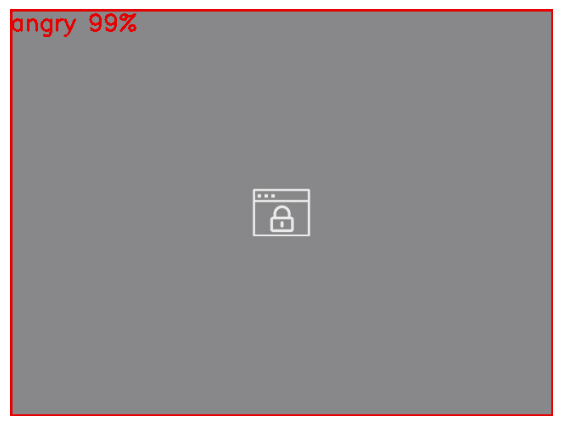

In [13]:
#emotion detection and adaptive responses
RESPONSES = {
    "happy":    "You look happy! That's great to see. Want a fun fact or some music?",
    "sad":      "You seem a little down. I'm here for you. Would you like a short breathing exercise?",
    "angry":    "I sense some frustration. Let's pause. Take a slow deep breath. Want me to simplify the task?",
    "fear":     "You look worried. Everything is okay. Let's take it one step at a time.",
    "surprise": "You look surprised! Would you like me to explain what just happened?",
    "disgust":  "That seems unpleasant. Shall I help you change or skip it?",
    "neutral":  "You look calm and focused. How can I help you today?",
}
COLORS = {"happy": (0,200,0), "sad": (200,100,0), "angry": (0,0,230), "fear": (150,0,150),
          "surprise": (0,200,200), "disgust": (0,120,60), "neutral": (160,160,160)}
mood_history = []

def analyze_emotion(path, speak=True):
    bgr = cv2.imread(path)
    res = DeepFace.analyze(bgr, actions=["emotion"], detector_backend="opencv", enforce_detection=False)
    if isinstance(res, dict): res = [res]
    vis = bgr.copy()
    for face in res:
        emo = face["dominant_emotion"]; scores = face["emotion"]
        r = face["region"]; x, y, w, h = r["x"], r["y"], r["w"], r["h"]
        cv2.rectangle(vis, (x, y), (x+w, y+h), COLORS[emo], 3)
        cv2.putText(vis, f"{emo} {scores[emo]:.0f}%", (x, max(25, y-10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, COLORS[emo], 2)
        mood_history.append(emo)
        print("Emotion scores:", {k: round(v, 1) for k, v in scores.items()})
        reply = RESPONSES[emo]
        print("\nAssistant:", reply)
        if speak:
            gTTS(reply).save("emo.mp3"); display(Audio("emo.mp3"))
    plt.figure(figsize=(7, 7)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

analyze_emotion(get_face_image())

Mood history: ['angry']


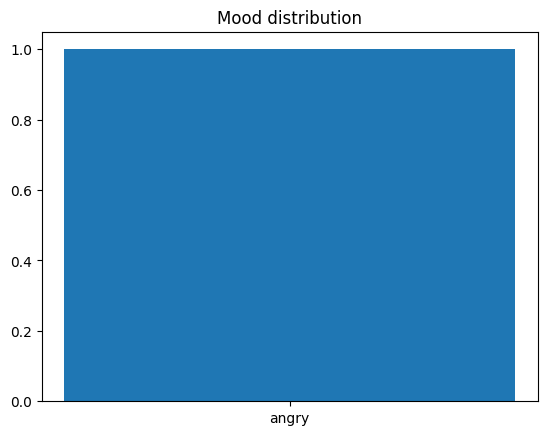

Assistant: You've seemed stressed lately. Consider taking a break or talking to someone you trust.


In [14]:
#mood tracking (run after a few captures)
def mood_summary():
    if not mood_history:
        print("No data yet."); return
    c = Counter(mood_history)
    print("Mood history:", mood_history)
    plt.bar(c.keys(), c.values()); plt.title("Mood distribution"); plt.show()
    negative = sum(c[k] for k in ("sad", "angry", "fear", "disgust"))
    if negative / len(mood_history) > 0.5:
        print("Assistant: You've seemed stressed lately. Consider taking a break or talking to someone you trust.")
    else:
        print("Assistant: You seem to be doing well overall. Keep it up!")

mood_summary()